In [54]:
import numpy as np;
import pandas as pd;
import matplotlib.pyplot as mp;
import seaborn as sns;

In [55]:
df=pd.read_csv('Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#Data Cleaning & Analysis


In [56]:

df.columns.to_list()


['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [57]:
df.shape

(7043, 21)

In [58]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [59]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [61]:
df.duplicated().sum()

np.int64(0)

In [62]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [63]:
for col in df.columns:
  print(col,df[col].unique())

customerID ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender ['Female' 'Male']
SeniorCitizen [0 1]
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
tenure [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (a

In [64]:
df['TotalCharges'].dtype

dtype('O')

In [65]:
df['TotalCharges'].value_counts().tail(10)

,count
TotalCharges,
6565.85,1
2117.2,1
203.95,1
6849.4,1
692.35,1
130.15,1
3211.9,1
7843.55,1
2196.3,1


Show row where total charges is blank

In [66]:
df[df['TotalCharges'].str.strip()=='']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [67]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')


In [68]:
df['TotalCharges'].isnull().sum()

np.int64(11)

Checking tenure , Monthly charges and total charges

In [69]:
df.loc[df['TotalCharges'].isna(),['tenure','MonthlyCharges','TotalCharges']]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [70]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [71]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [72]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Our main business question is:

Why are customers leaving the telecom company?

In [73]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [74]:
churn_rate = (df['Churn'] == 'Yes').mean() * 100
churn_rate

np.float64(26.536987079369588)

Are month-to-month customers more likely to leave than customers on longer contracts?

In [75]:
pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [76]:
df.groupby('Churn')['tenure'].mean()

,tenure
Churn,
No,37.569965
Yes,17.979133


Customers who churned had an average tenure of only ~18 months, compared with ~38 months for customers who stayed.

Newer customers are substantially more likely to churn than long-term customers.

Churn by Internet Service

In [77]:
pd.crosstab(df['InternetService'], df['Churn'], normalize='index') * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


Fiber optics has higher churn rate


In [78]:
pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index') * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


The customer with Electronic check has a higher churn rate .


In [79]:
df.groupby('Churn')['MonthlyCharges'].mean()


,MonthlyCharges
Churn,
No,61.265124
Yes,74.441332


Customers who pay more churn more Asumption

In [80]:
df.dtypes


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


  Using Numpy to create Churn flag

In [81]:
df['ChurnFlag'] = np.where(df['Churn'] == 'Yes', 1, 0)

In [82]:
df[['Churn', 'ChurnFlag']].head()

,Churn,ChurnFlag
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [83]:
churn_rate=np.mean(df['ChurnFlag'])*100
churn_rate

np.float64(26.536987079369588)

In [84]:
mavg_charges=df.groupby('Churn')['MonthlyCharges'].mean()
difference=mavg_charges['Yes']-mavg_charges['No']
difference

np.float64(13.176208567842295)

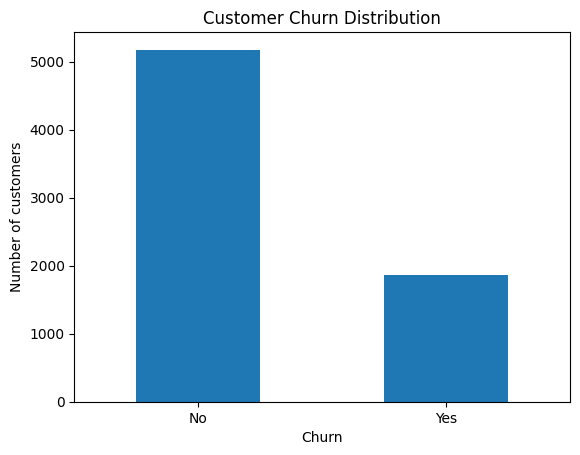

In [85]:
df['Churn'].value_counts().plot(kind='bar')
mp.title('Customer Churn Distribution')
mp.xlabel('Churn')
mp.ylabel('Number of customers')
mp.xticks(rotation=0)
mp.show()

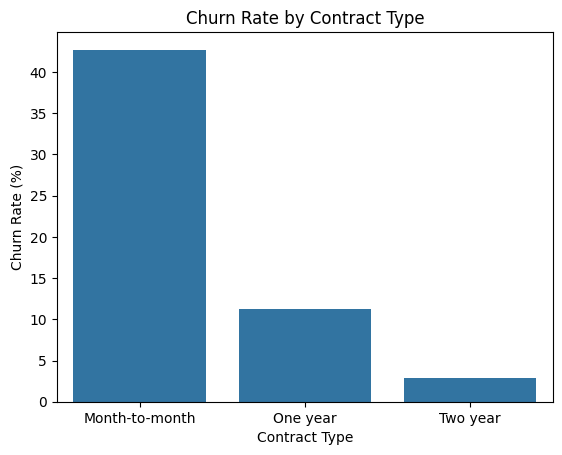

In [86]:
contract_churn = pd.crosstab( df['Contract'],df['Churn'],normalize='index') * 100
sns.barplot( x=contract_churn.index,y=contract_churn['Yes'])

mp.title('Churn Rate by Contract Type')
mp.xlabel('Contract Type')
mp.ylabel('Churn Rate (%)')
mp.xticks(rotation=0)
mp.show()

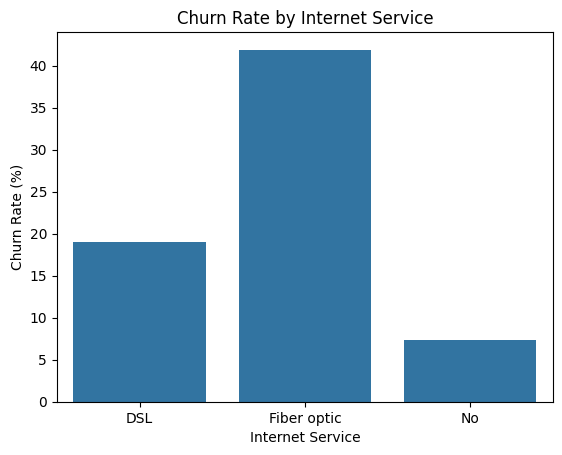

In [87]:
internet_churn=pd.crosstab(df['InternetService'],df['Churn'],normalize='index')*100
sns.barplot(x=internet_churn.index,y=internet_churn['Yes'])
mp.title('Churn Rate by Internet Service')
mp.xlabel('Internet Service')
mp.ylabel('Churn Rate (%)')
mp.xticks(rotation=0)
mp.show()

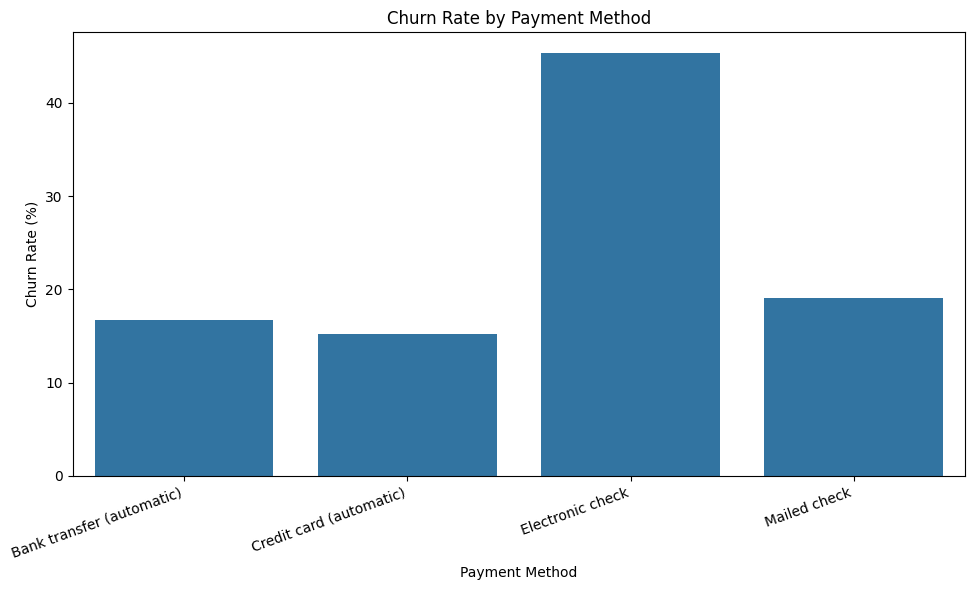

In [91]:
payment_churn=pd.crosstab(df['PaymentMethod'],df['Churn'],normalize='index')*100
mp.figure(figsize=(10, 6))
sns.barplot(x=payment_churn.index,y=payment_churn['Yes'])

mp.title('Churn Rate by Payment Method')
mp.xlabel('Payment Method')
mp.ylabel('Churn Rate (%)')
mp.xticks(rotation=20,ha='right')
mp.tight_layout()
mp.show()

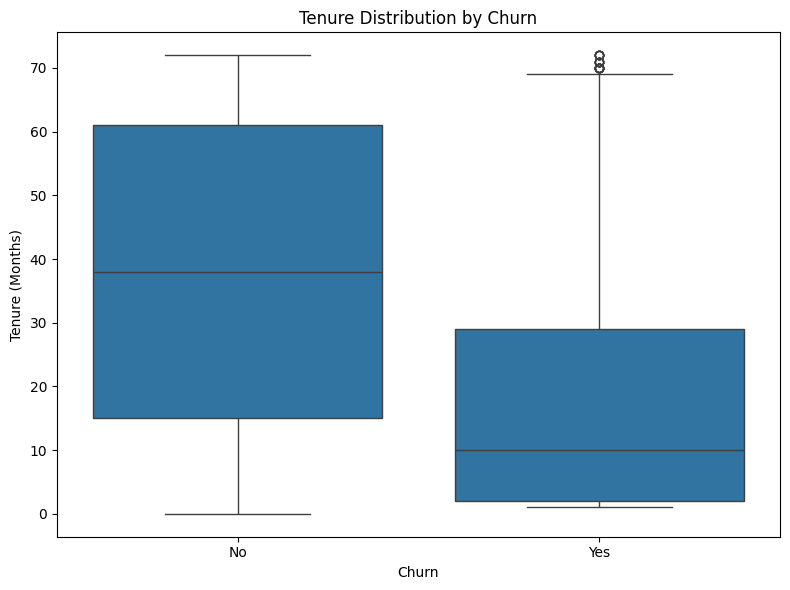

In [92]:
mp.figure(figsize=(8, 6))

sns.boxplot(x='Churn',y='tenure',data=df)

mp.title('Tenure Distribution by Churn')
mp.xlabel('Churn')
mp.ylabel('Tenure (Months)')

mp.tight_layout()
mp.show()

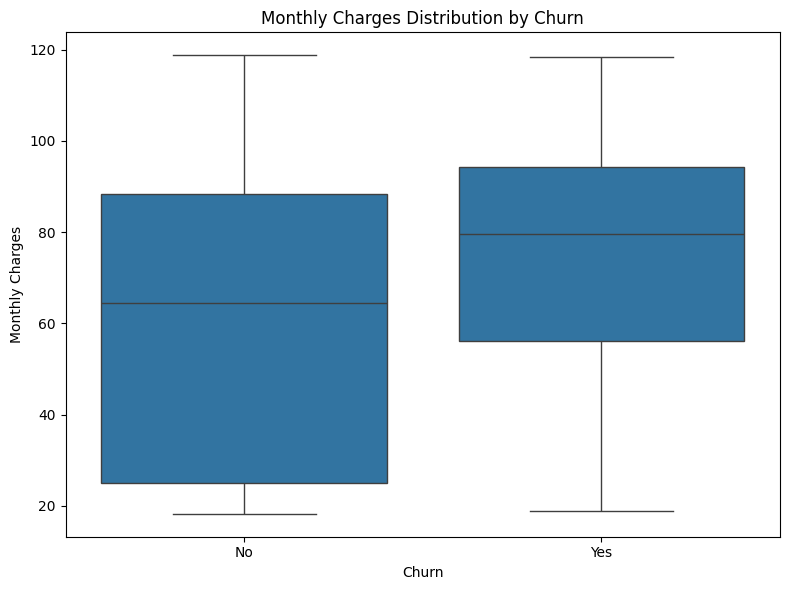

In [93]:
mp.figure(figsize=(8, 6))

sns.boxplot(x='Churn',y='MonthlyCharges',data=df)

mp.title('Monthly Charges Distribution by Churn')
mp.xlabel('Churn')
mp.ylabel('Monthly Charges')

mp.tight_layout()
mp.show()

correlation heatmap

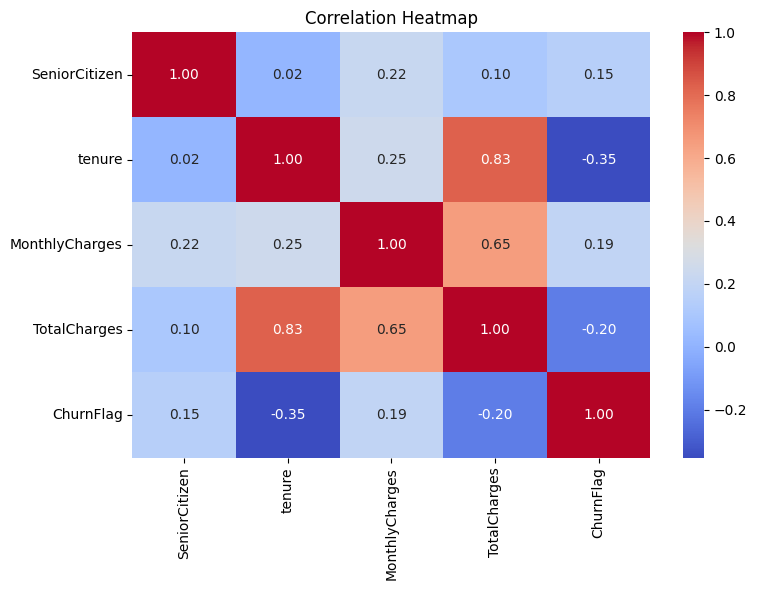

In [94]:
cor = df[
    ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']
].corr()

mp.figure(figsize=(8, 6))

sns.heatmap(
    cor,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

mp.title('Correlation Heatmap')
mp.tight_layout()
mp.show()

In [95]:
df.to_csv('telco_churn_cleaned.csv', index=False)

In [96]:
import os

print(os.path.exists('telco_churn_cleaned.csv'))

True
